# Function 3 - Week 5: cohort model comparison

Start with the [cohort exploration review](cohort-exploration-review.ipynb). This copy adds five
previously accepted peer returns to the **19 official observations**, giving **24 rows**.
The peer snapshot is pinned to 20 October 2026; own feedback is current through round 4 on
23 October. Shared initial rows are included once and all three inputs remain active.

Retain the seven declared model families, GP bounds, noise assumption and acquisition settings
from the [official model notebook](model_predictions.ipynb). Compare pooled leave-one-out checks,
the same 19 official held-out targets, and both policies on one common candidate pool. The plots
retain full 3D hull masking and distinguish conditional planes from projections.

Peer returns are public self-reports, with possible rounding and transcription errors. No source
refresh, new function evaluation or portal submission occurs. The official proposal stays intact.


In [2]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.spatial import Delaunay
from scipy.spatial.distance import cdist
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

week_dir = Path.cwd().resolve()
if not (week_dir / 'cohort-model_predictions.ipynb').is_file() or not (week_dir / 'cohort-observations.csv').is_file():
    raise FileNotFoundError('Run from Function_3/Week_05 with both data CSVs and the cohort notebook together.')
shared_dir = week_dir.parents[1] / 'Shared'
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from model_helpers import compare_models, make_query_candidates, score_query_candidates, gp_slice
from coverage_helpers import make_coverage_space
from coverage_cache import compare_coverage_batches
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from plot_helpers import PLOT_CONFIG
from three_input_model_helpers import (
    PLANE_AXES, input_cloud, plot_coordinate_curves, plane_grid, build_plane_slices,
    plot_contour_sections, plot_gp_score_sections, interactive_terrain_slices,
)

figures = week_dir / 'figures' / 'cohort'
figures.mkdir(parents=True, exist_ok=True)
print('Kernel:', sys.executable)


Kernel: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


## 1. Define the goal and scope

Examine how five retained peer returns change the Function 3 fit, uncertainty and proposed
Week 5 point. Compare with the official proposal without replacing it. Nine owner weekly
queries remain; peer observations do not increase that allowance.

## 2. Gather the data

The local pooled CSV contains 19 official rows followed by the five accepted peer rows from
[the previous cohort study](../../../side-quests/cohort-2026-10-20/README.md). Source hashes were
checked against retained files and the earlier own rows reconciled through round 3. The shared
initial observations appear once. Pending outputs, invalid inputs and compatible duplicate
reports remain excluded; distinct inputs with equal reported outputs are retained.


In [3]:
data = pd.read_csv(week_dir/'cohort-observations.csv',float_precision='round_trip')
own_data = pd.read_csv(week_dir/'observations.csv',float_precision='round_trip')
input_columns = ['x1','x2','x3']
output_column = 'y'
if list(data.columns) != ['observation_id','source_round',*input_columns,'y'] or len(data)!=24 or len(own_data)!=19:
    raise ValueError('Expected 19 official observations plus five retained peer returns.')
if data.isna().any().any() or not data.observation_id.is_unique:
    raise ValueError('Require complete rows with distinct observation IDs.')
pd.testing.assert_frame_equal(data.iloc[:len(own_data)].reset_index(drop=True),own_data)
own_mask = data.observation_id.isin(own_data.observation_id).to_numpy()
peer_mask = data.observation_id.str.startswith('peer-').to_numpy()
assert own_mask.sum()==19 and peer_mask.sum()==5 and (own_mask|peer_mask).all()
assert data.loc[own_mask,'source_round'].value_counts().to_dict()=={0:15,1:1,2:1,3:1,4:1}
assert data.loc[peer_mask,'source_round'].max()<=2
X,y = data[input_columns],data.y
inputs,raw_y = X.to_numpy(dtype=float),y.to_numpy(dtype=float)
if not np.isfinite(np.column_stack([inputs,raw_y])).all() or not ((inputs>=0)&(inputs<1)).all():
    raise ValueError('Require finite observations with inputs in [0,1).')
print(f'{len(data)} observations: {own_mask.sum()} official and {peer_mask.sum()} peer rows.')
print(f'Owner query allowance including Week 5: {remaining_queries(week_dir)} of {TOTAL_QUERY_WEEKS}.')


24 observations: 19 official and 5 peer rows.
Owner query allowance including Week 5: 9 of 13.


## 3. Explore the data

The [cohort review](cohort-exploration-review.ipynb) retains the measured-output views and
three-input cloud. The owner's latest output **-0.0566421241758** ranks **10/24 (1 = highest)**.
The pooled incumbent remains **-0.0348353133501**. The latest owner return is identified
explicitly; peer iteration numbers are not an owner query sequence.


In [4]:
# Identify the one new observation in this week's accumulated data.
latest_round = int(own_data["source_round"].max())
latest_indices = data.index[own_mask & data["source_round"].eq(latest_round)]
if latest_round == 0 or len(latest_indices) != 1:
    raise ValueError("This weekly comparison expects one latest returned observation.")
latest_index = latest_indices[0]
latest_position = X.index.get_loc(latest_index)
latest_output = float(y.loc[latest_index])
other_observations = data.observation_id.ne(data.loc[latest_index,"observation_id"]).to_numpy()

print(f"Latest observation: {data.loc[latest_index, 'observation_id']}")
print(f"Latest output: {latest_output:.6f}")
print(f"Previous best: {y.loc[data['source_round'].lt(latest_round)].max():.6f}")
print("Maximise the original signed output; retain negative and positive results.")
data.loc[[latest_index], ["observation_id", *input_columns, output_column]]

Latest observation: round-04
Latest output: -0.056642
Previous best: -0.034835
Maximise the original signed output; retain negative and positive results.


,observation_id,x1,x2,x3,y
18,round-04,0.903842,0.268903,0.8752,-0.056642


## 4. Clean and preprocess the data

Retain all observations, signs and full float64 precision. Inputs already share `[0, 1)`.
Use raw output units throughout, with no log transform or clipping of predictions to zero.
GP target normalisation and kernel fitting happen inside each training fold. The noise SD
assumption is 10% of the training output SD; no identical-input repeats establish that level.

## 5. Select and engineer features

Preserve the original ordered coordinates `x1, x2, x3`. All full models use all three.
The existing quadratic hypothesis adds the three squares and three pairwise interactions;
feature scaling stays inside its training pipeline. Separate GP length scales can represent
differing coordinate relevance without silently dropping any input.

## 6. Define the machine-learning task

Regress the numerical output to support maximisation. Predicting observed outputs accurately
and locating a better unseen maximum are different assessments.

## 7. Partition the data

Use 24 leave-one-out folds: train on 23 observations and score the held-out one. No separate
final test set is used for this small adaptive study. The latest-result fold trains on the 18 earlier official rows plus five frozen peer rows, but these model settings are declared now, so it remains a retrospective
check. Reusing folds to compare methods can make the winning error optimistic.

## 8. Select and train candidate methods

Retain the established mean, ordinary linear, ridge (`alpha=1`) and RBF kernel-ridge
(`alpha=0.1`, `gamma=1`) comparisons. Carry forward Function 3's quadratic ridge (`alpha=1`)
with its training-fold feature scaling. Compare constant-times-RBF GPs with either one fitted
length scale or one per input, using bounds `0.03â€“2.0`, a 10% noise assumption and three seeded
optimiser restarts. These are a declared small comparison, not an open-ended parameter search.

Peer observations are adaptively chosen, may cluster, and have differing reported precision.
Keep the original 10% training-target-SD noise assumption as a controlled comparison, not an
estimated peer-noise model. Full pooled and official LOO metrics score different target sets;
the final paired comparison holds the 19 official targets fixed.


In [5]:
noise_fraction = 0.10
models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Linear regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Kernel ridge': KernelRidge(alpha=0.1, kernel='rbf', gamma=1.0),
    'Quadratic ridge': make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), Ridge(alpha=1.0),
    ),
    'Gaussian process': GaussianProcessRegressor(
        kernel=ConstantKernel(1.0, (0.01, 100.0))*RBF(0.3, (0.03, 2.0)),
        alpha=noise_fraction**2, normalize_y=True, n_restarts_optimizer=3, random_state=42,
    ),
}
models['GP: separate length scales'] = clone(models['Gaussian process']).set_params(
    kernel=ConstantKernel(1.0, (0.01, 100.0))*RBF([0.3, 0.3, 0.3], (0.03, 2.0)),
)
comparison, held_out_predictions, fitted_models = compare_models(models, inputs, raw_y)
baseline_rmse = float(comparison.loc['Mean baseline', 'LOO RMSE'])
gp_names = ['Gaussian process', 'GP: separate length scales']
best_gp_name = comparison.loc[gp_names, 'LOO RMSE'].idxmin()
gaussian_process_rmse = float(comparison.loc[best_gp_name, 'LOO RMSE'])
model_comparison = comparison.reset_index()
model_comparison['RMSE reduction (%)'] = 100*(1-model_comparison['LOO RMSE']/baseline_rmse)
model_comparison = model_comparison.sort_values('LOO RMSE').reset_index(drop=True)
display(model_comparison.round(6))


C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better 

,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,Gaussian process,0.001381,0.041774,0.049440,0.712366,49.425516
1,Kernel ridge,0.035576,0.059166,0.075843,1.008962,22.415768
2,GP: separate length scales,0.001573,0.064509,0.079026,1.100079,19.159874
3,Ridge,0.056104,0.065116,0.091843,1.110434,6.049312
4,Quadratic ridge,0.044701,0.070633,0.092136,1.204500,5.748637
5,Linear regression,0.059037,0.073533,0.096685,1.253954,1.095187
6,Mean baseline,0.056197,0.058641,0.097756,1.000000,0.000000


In [6]:
# Inspect the latest-result fold: train on other retained observations and predict the new one.
# Model settings were chosen for this analysis, so this is a retrospective check.
# The other-row metric below uses folds that include the latest observation in training.
latest_rows = []
for name, predictions in held_out_predictions.items():
    residuals = predictions - y.to_numpy()
    latest_prediction = float(predictions[latest_position])
    latest_error = latest_prediction - latest_output
    latest_rows.append({
        "Model": name,
        "Latest held-out prediction": latest_prediction,
        "Latest error": latest_error,
        "Latest absolute error (%)": 100 * abs(latest_error) / abs(latest_output),
        "Latest share of squared error (%)": 100 * latest_error ** 2 / np.sum(residuals ** 2),
        "Other rows LOO RMSE": root_mean_squared_error(
            y.to_numpy()[other_observations], predictions[other_observations],
        ),
    })
latest_prediction_review = pd.DataFrame(latest_rows).sort_values("Latest absolute error (%)").reset_index(drop=True)
print(f"Actual latest output: {latest_output:.6f}")
print(f"Each prediction of this latest output used only the {other_observations.sum()} other retained observations.")
print("Other rows LOO RMSE excludes this row from scoring, not from their training folds.")
latest_prediction_review.round(4)

Actual latest output: -0.056642
Each prediction of this latest output used only the 23 other retained observations.
Other rows LOO RMSE excludes this row from scoring, not from their training folds.


,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,Kernel ridge,-0.0841,-0.0275,48.5640,0.5481,0.0773
1,GP: separate length scales,-0.1068,-0.0501,88.5028,1.6766,0.0800
2,Mean baseline,-0.1088,-0.0521,92.0454,1.1852,0.0993
3,Gaussian process,-0.1094,-0.0528,93.1492,4.7454,0.0493
4,Quadratic ridge,-0.1103,-0.0537,94.7463,1.4136,0.0935
5,Ridge,-0.1425,-0.0859,151.6247,3.6435,0.0921
6,Linear regression,-0.1577,-0.1010,178.3838,4.5505,0.0965


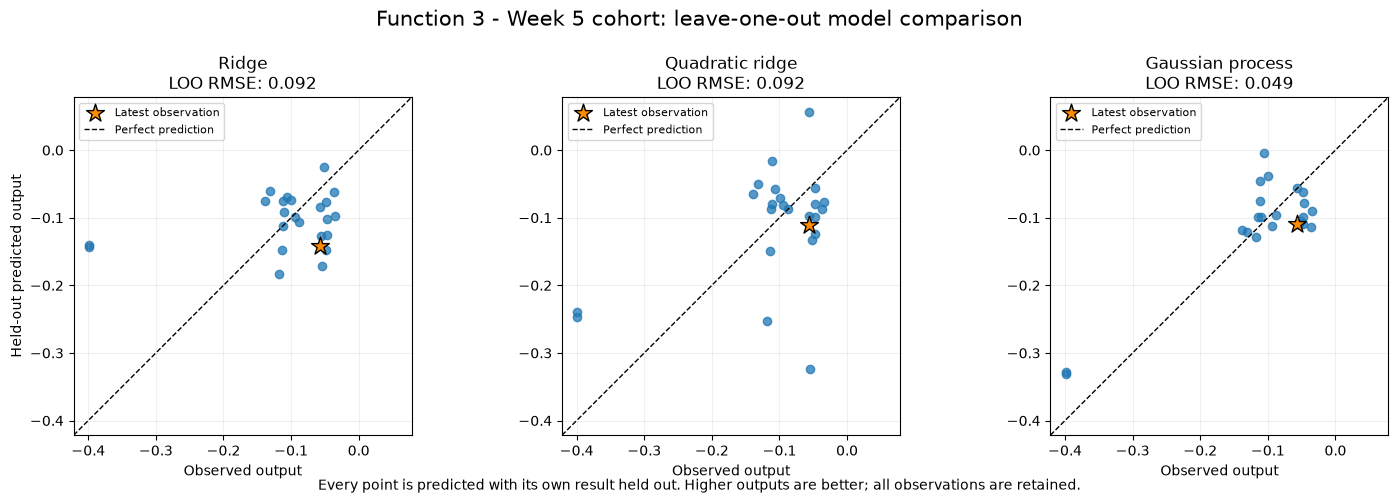

In [7]:
# Compare the linear and nonlinear alternatives on the same output scale.
plot_models = ["Ridge", "Quadratic ridge", best_gp_name]
plot_values = np.concatenate([
    y.to_numpy(), *(held_out_predictions[name] for name in plot_models),
])
plot_padding = 0.05 * np.ptp(plot_values)
plot_limits = (
    float(plot_values.min() - plot_padding),
    float(plot_values.max() + plot_padding),
)

fig, axes = plt.subplots(1, len(plot_models), figsize=(15, 5))
for ax, name in zip(axes, plot_models):
    predictions = held_out_predictions[name]
    ax.scatter(y.to_numpy()[other_observations], predictions[other_observations], alpha=0.75)
    ax.scatter(
        latest_output, predictions[latest_position], marker="*", s=180,
        color="darkorange", edgecolor="black", label="Latest observation",
    )
    ax.plot(plot_limits, plot_limits, "k--", linewidth=1, label="Perfect prediction")
    ax.set(
        xlim=plot_limits, ylim=plot_limits, xlabel="Observed output",
        title=f"{name}\nLOO RMSE: {root_mean_squared_error(y, predictions):.3f}",
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Held-out predicted output")
fig.suptitle("Function 3 - Week 5 cohort: leave-one-out model comparison", fontsize=15)
fig.text(
    0.5, 0.02,
    "Every point is predicted with its own result held out. Higher outputs are better; all observations are retained.",
    ha="center", fontsize=10,
)
fig.tight_layout(rect=(0, 0.055, 1, 0.95))
fig.savefig(figures / "model-comparison-validation.png", dpi=160, bbox_inches="tight")
plt.show()

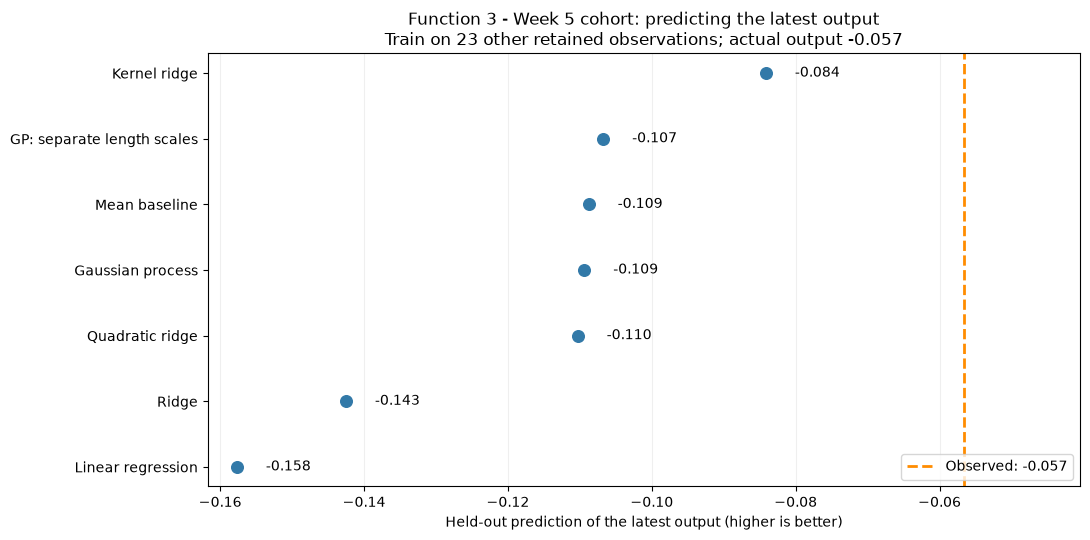

In [8]:
# Compare each model's held-out prediction with the latest result.
latest_chart = latest_prediction_review.sort_values("Latest held-out prediction", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5.5))
positions = np.arange(len(latest_chart))
values = latest_chart["Latest held-out prediction"].to_numpy()
ax.scatter(values, positions, color="#3279a8", s=70, zorder=3)
ax.set_yticks(positions, latest_chart["Model"])
ax.invert_yaxis()
ax.axvline(
    latest_output, color="darkorange", linewidth=2, linestyle="--",
    label=f"Observed: {latest_output:.3f}",
)
chart_min = min(latest_output, values.min())
chart_max = max(latest_output, values.max())
chart_padding = 0.04 * (chart_max - chart_min)
for position, value in zip(positions, values):
    ax.text(value + chart_padding, position, f"{value:.3f}", va="center", fontsize=10)
ax.set_xlim(chart_min - chart_padding, chart_max + 4 * chart_padding)
ax.set_xlabel("Held-out prediction of the latest output (higher is better)")
ax.set_title(
    f"Function 3 - Week 5 cohort: predicting the latest output\n"
    f"Train on {other_observations.sum()} other retained observations; actual output {latest_output:.3f}"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(figures / "latest-output-predictions.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Evaluate and interpret the results

Compare overall held-out RMSE and MAE, the latest-result fold, and the differences between
models before reviewing a proposal. Training fit alone is not validation evidence.
Select the lower-LOO-RMSE GP for UCB because it supplies a mean and conditional uncertainty;
a different regressor may still predict held-out outputs better. If neither GP beats the
mean baseline, label its proposal as exploratory rather than claiming predictive support.


In [9]:
# Summarise the evidence before moving on to query selection.
lowest_rmse = model_comparison.iloc[0]
lowest_mae = model_comparison.loc[model_comparison["LOO MAE"].idxmin()]
closest_latest = latest_prediction_review.iloc[0]
lowest_rmse_latest = latest_prediction_review.loc[
    latest_prediction_review["Model"].eq(lowest_rmse["Model"])
].iloc[0]

print(f"Lowest overall LOO RMSE: {lowest_rmse['Model']} ({lowest_rmse['LOO RMSE']:.4f}).")
print(f"RMSE reduction against mean baseline: {lowest_rmse['RMSE reduction (%)']:.1f}%.")
print(f"Lowest overall LOO MAE: {lowest_mae['Model']} ({lowest_mae['LOO MAE']:.4f}).")
print(
    f"Closest prediction of the latest held-out result: {closest_latest['Model']}, "
    f"{closest_latest['Latest held-out prediction']:.4f} versus actual {latest_output:.4f}."
)
print(f"Its absolute error on that result: {closest_latest['Latest absolute error (%)']:.1f}%.")
print(
    f"The latest result contributes {lowest_rmse_latest['Latest share of squared error (%)']:.1f}% "
    "of the lowest-RMSE model's total held-out squared error."
)
print("Overall prediction error and ability to locate a better maximum are different assessments.")
print("This comparison does not establish the location or value of the global maximum.")
print("Model comparison is complete; query selection follows below.")

Lowest overall LOO RMSE: Gaussian process (0.0494).
RMSE reduction against mean baseline: 49.4%.
Lowest overall LOO MAE: Gaussian process (0.0418).
Closest prediction of the latest held-out result: Kernel ridge, -0.0841 versus actual -0.0566.
Its absolute error on that result: 48.6%.
The latest result contributes 4.7% of the lowest-RMSE model's total held-out squared error.
Overall prediction error and ability to locate a better maximum are different assessments.
This comparison does not establish the location or value of the global maximum.
Model comparison is complete; query selection follows below.


In [10]:
selected_model = fitted_models[best_gp_name]
relative_gp_error = gaussian_process_rmse/baseline_rmse
print('Query model:', best_gp_name)
print('Lowest-RMSE model overall:', model_comparison.iloc[0]['Model'])
print(f'Selected GP / baseline held-out RMSE: {relative_gp_error:.6f}')
print('Fitted kernel:', selected_model.kernel_)
if relative_gp_error >= 1:
    print('The GP does not beat the mean baseline. Treat its UCB suggestion as exploratory.')
else:
    print('This GP beats the mean baseline on these folds; this does not guarantee a better maximum.')


Query model: Gaussian process
Lowest-RMSE model overall: Gaussian process
Selected GP / baseline held-out RMSE: 0.505745
Fitted kernel: 0.854**2 * RBF(length_scale=0.151)
This GP beats the mean baseline on these folds; this does not guarantee a better maximum.


### Inspect curves and conditional planes in the three-input space

Three coordinate curves pass through the incumbent, holding its other two coordinates fixed.
Compare both GP explanations with shared vertical limits. Green crosses match both held
coordinates; measurements elsewhere are not projected onto the curves. Bands are pointwise
mean Â± 1.96 latent-function SD under each model's assumptions, excluding new observation noise.

Each contour plane varies two inputs and fixes the third. Compare kernel ridge and the selected
GP through the incumbent on one output colour scale. Masking uses the full **3D sampled hull**,
rather than an input-pair projection. Blank regions are outside that hull. Rotatable fitted
terrains repeat the sections at seven held values; their surfaces remain model predictions.


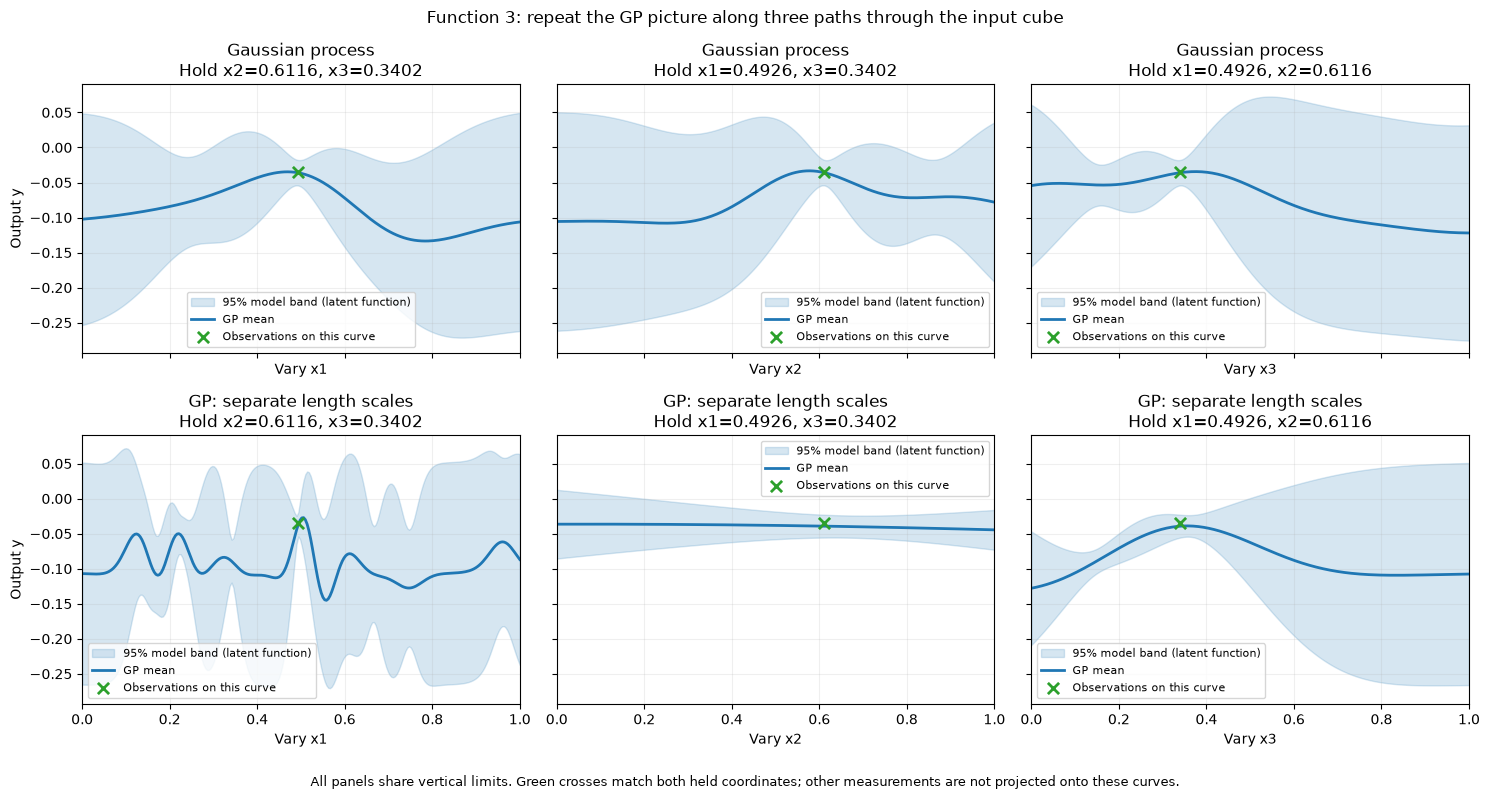

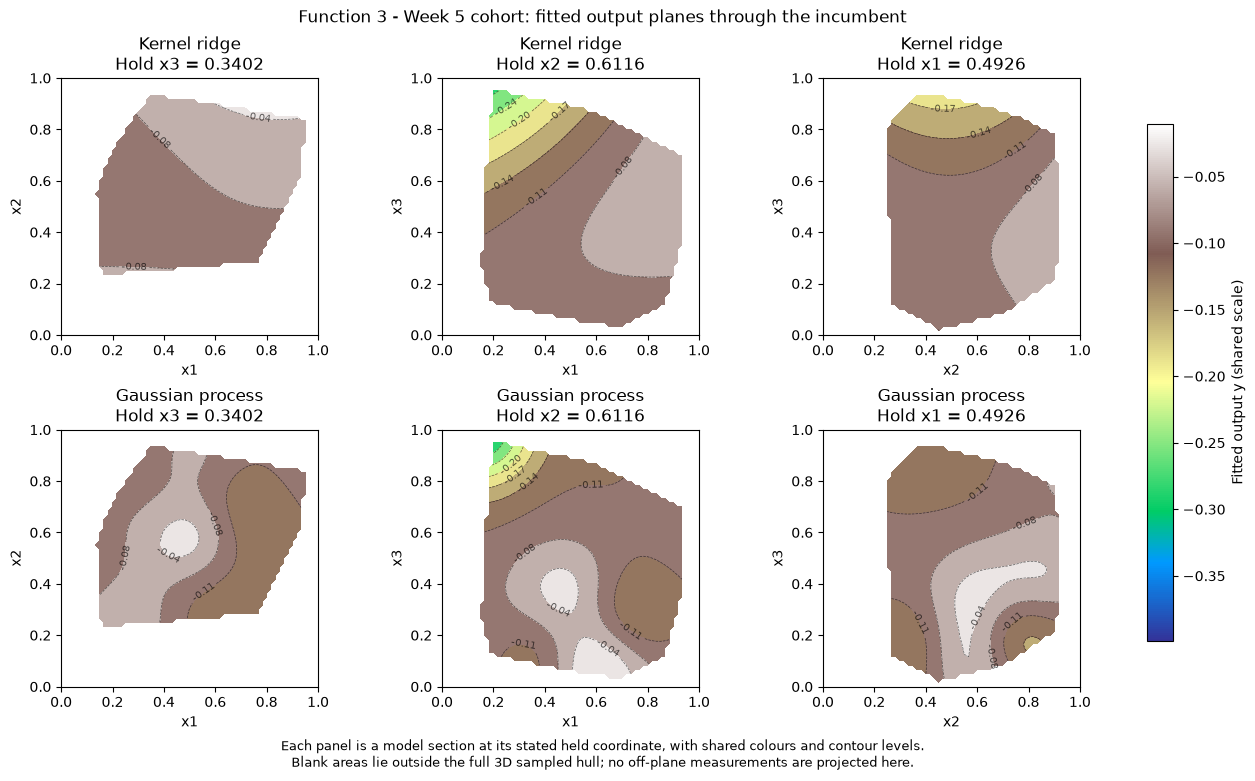

In [11]:
best_position = int(np.argmax(raw_y))
anchor = inputs[best_position].copy()
display(plot_coordinate_curves(
    {name: fitted_models[name] for name in gp_names}, inputs, raw_y, anchor,
    save_to=figures/'gp-coordinate-slices.png',
))
contour_rows = []
for name in ['Kernel ridge', best_gp_name]:
    grids = [plane_grid(fitted_models[name], inputs, (a,b), anchor[c]) for a,b,c in PLANE_AXES]
    contour_rows.append((name, grids))
display(plot_contour_sections(contour_rows, raw_y,
    title='Function 3 - Week 5 cohort: fitted output planes through the incumbent',
    save_to=figures/'fitted-output-contour-slices.png'))
slice_values = np.array([0.10, 0.25, 0.40, 0.50, 0.60, 0.75, 0.90])
fitted_slices = build_plane_slices(selected_model, inputs, slice_values)
terrain = interactive_terrain_slices(fitted_slices, slice_values, raw_y,
    title=f'Function 3 - Week 5 cohort: {best_gp_name} conditional terrains',
    save_to=figures/'fitted-terrain-slices.html')
terrain.show(config=PLOT_CONFIG)


### Compare broad search, local refinement and a coverage alternative

Use $\mathrm{UCB}(x)=\mu(x)+1.96\sigma(x)$, the same rule as the other functions.
A high score can come from predicted output, uncertainty, or both; it is not a returned score.
Compare 16,384 seeded broad Sobol points plus the eight extreme corners, a local pool within
0.15 of the incumbent in each of the three coordinates, and one independently optimised
pure-coverage point. Local radius and exploration weight remain declared heuristics.

Round all coordinates to six decimals **before** predicting. Remove duplicate and previously
observed inputs at portal precision. All three inputs remain free throughout candidate generation and scoring. The winner is the best of a finite pool, not a proven
continuous optimum. The pure-coverage gap metric concerns geometry, not improvement in output.


In [12]:
broad = pd.DataFrame(make_query_candidates(inputs, power=14, seed=42), columns=input_columns)
local_offsets = make_coverage_space(3, power=12, seed=43)
local = pd.DataFrame(np.clip(anchor+0.30*(local_offsets-0.5), 0, 0.999999), columns=input_columns)
coverage_comparison = compare_coverage_batches(
    existing=inputs, cache_dir=week_dir/'.coverage-cache'/'cohort', max_queries=1,
)
coverage = pd.DataFrame(coverage_comparison['proposed_batches'][1], columns=input_columns)
candidates = pd.concat([
    broad.assign(candidate_source='Full input space'),
    local.assign(candidate_source='Near incumbent'),
    coverage.assign(candidate_source='Single coverage query'),
], ignore_index=True)
candidates[input_columns] = candidates[input_columns].round(6).clip(0,0.999999)
candidates = candidates.drop_duplicates(subset=input_columns)
observed_coordinates = set(map(tuple, inputs.round(6)))
candidates = candidates.loc[[tuple(p) not in observed_coordinates for p in candidates[input_columns].to_numpy()]]
exploration_weight = 1.96
scored = score_query_candidates(selected_model, candidates[input_columns].to_numpy(), weight=exploration_weight)
scored = scored.merge(candidates, on=input_columns, how='left', validate='one_to_one')
candidate_comparison = scored.loc[scored.groupby('candidate_source')['ucb'].idxmax()].sort_values('ucb', ascending=False)
display(candidate_comparison.round(6))
print(f'{len(scored):,} unique unobserved three-input candidate locations.')
print('Coverage alternative:', '-'.join(f'{v:.6f}' for v in coverage.iloc[0].round(6)))
before = coverage_comparison['results'][0]['max_distance']
after = coverage_comparison['results'][1]['max_distance']
print(f'Pure coverage reduces the separately assessed worst sampling gap by {1-after/before:.1%}.')


q=0: computed and saved


q=1: computed and saved


,x1,x2,x3,posterior_mean,posterior_sd,ucb,candidate_source
0,0.658460,0.558234,0.006012,-0.033284,0.065885,0.095850,Full input space
50,0.389705,0.720420,0.486762,-0.052781,0.066360,0.077284,Near incumbent
2171,0.824596,0.878204,0.768531,-0.093086,0.077297,0.058417,Single coverage query


20,497 unique unobserved three-input candidate locations.
Coverage alternative: 0.824596-0.878204-0.768531
Pure coverage reduces the separately assessed worst sampling gap by 0.0%.


In [13]:
recommended = scored.iloc[0]
next_query = recommended[input_columns].to_numpy(dtype=float)
proposal_source = recommended.candidate_source
assert np.isfinite(next_query).all() and ((next_query >= 0) & (next_query < 1)).all()
assert np.array_equal(next_query, next_query.round(6)) and tuple(next_query) not in observed_coordinates
portal_input = '-'.join(f'{value:.6f}' for value in next_query)
next_mean, next_std = selected_model.predict(next_query[None, :], return_std=True)
inside_hull = bool(Delaunay(inputs).find_simplex(next_query) >= 0)
print('Proposed next query (input-column order):')
print(', '.join(f'{name}={value:.6f}' for name, value in zip(input_columns, next_query)))
print('Portal input:', portal_input)
print('Candidate source:', proposal_source)
print(f'Best observed output: {raw_y.max():.6f}')
print(f'Predicted output at the proposed query: {next_mean[0]:.6f}')
print(f'Posterior standard deviation: {next_std[0]:.6f}')
print(f'Predicted mean improvement: {next_mean[0]-raw_y.max():+.6f}')
print(f'UCB acquisition score: {next_mean[0]+exploration_weight*next_std[0]:.6f}')
print('Inside sampled hull:', inside_hull)
print('This is a model-based proposal, not a guaranteed improvement or a submission.')
noise_rows = []
for fraction in (0.03, noise_fraction, 0.30):
    model = selected_model if fraction == noise_fraction else clone(selected_model).set_params(alpha=fraction**2).fit(inputs, raw_y)
    mean, std = model.predict(next_query[None, :], return_std=True)
    noise_rows.append({'Assumed noise fraction': fraction, 'Predicted output': mean[0], 'Posterior SD': std[0]})
print('Noise sensitivity at the same proposed point (refitting under each assumption):')
display(pd.DataFrame(noise_rows).round(6))
weight_rows = []
for weight in (0.0, 1.0, 1.96, 3.0):
    scores = scored.posterior_mean + weight * scored.posterior_sd
    alternative = scored.loc[scores.idxmax()]
    alternative_point = alternative[input_columns].to_numpy(dtype=float)
    weight_rows.append({'Weight': weight, **dict(zip(input_columns, alternative_point)),
                        'Predicted output': alternative.posterior_mean, 'Posterior SD': alternative.posterior_sd})
exploration_sensitivity = pd.DataFrame(weight_rows)
print('Exploration-weight sensitivity (same candidate pool and predictions):')
display(exploration_sensitivity.round(6))
distinct_choices = len(exploration_sensitivity[input_columns].drop_duplicates())
print(f'{distinct_choices} distinct locations across {len(exploration_sensitivity)} weights.')


Proposed next query (input-column order):
x1=0.658460, x2=0.558234, x3=0.006012
Portal input: 0.658460-0.558234-0.006012
Candidate source: Full input space
Best observed output: -0.034835
Predicted output at the proposed query: -0.033284
Posterior standard deviation: 0.065885
Predicted mean improvement: +0.001551
UCB acquisition score: 0.095850
Inside sampled hull: False
This is a model-based proposal, not a guaranteed improvement or a submission.
Noise sensitivity at the same proposed point (refitting under each assumption):


,Assumed noise fraction,Predicted output,Posterior SD
0,0.03,-0.038905,0.070302
1,0.10,-0.033284,0.065885
2,0.30,-0.076600,0.042312


Exploration-weight sensitivity (same candidate pool and predictions):


,Weight,x1,x2,x3,Predicted output,Posterior SD
0,0.00,0.630527,0.618256,0.048405,-0.010471,0.044519
1,1.00,0.616468,0.622577,0.007144,-0.011943,0.049858
2,1.96,0.658460,0.558234,0.006012,-0.033284,0.065885
3,3.00,0.658460,0.558234,0.006012,-0.033284,0.065885


3 distinct locations across 4 weights.


### Locate the proposal without flattening away an input

The cloud keeps `x1, x2, x3` as input axes and measured output as colour. The gold diamond
is the incumbent; the magenta X is the proposed unevaluated input, with no invented output.

The acquisition matrix shows three **conditional planes through the proposal**, so the
magenta X is on each plane. Each column shares its own colour scale. Black dots appear only
when both displayed coordinates belong to a measurement matching the held coordinate.
The dotted line is the intersection with the full 3D sampled hull; coloured regions outside
it are explicit extrapolations. These planes are not projections of all observed outputs.


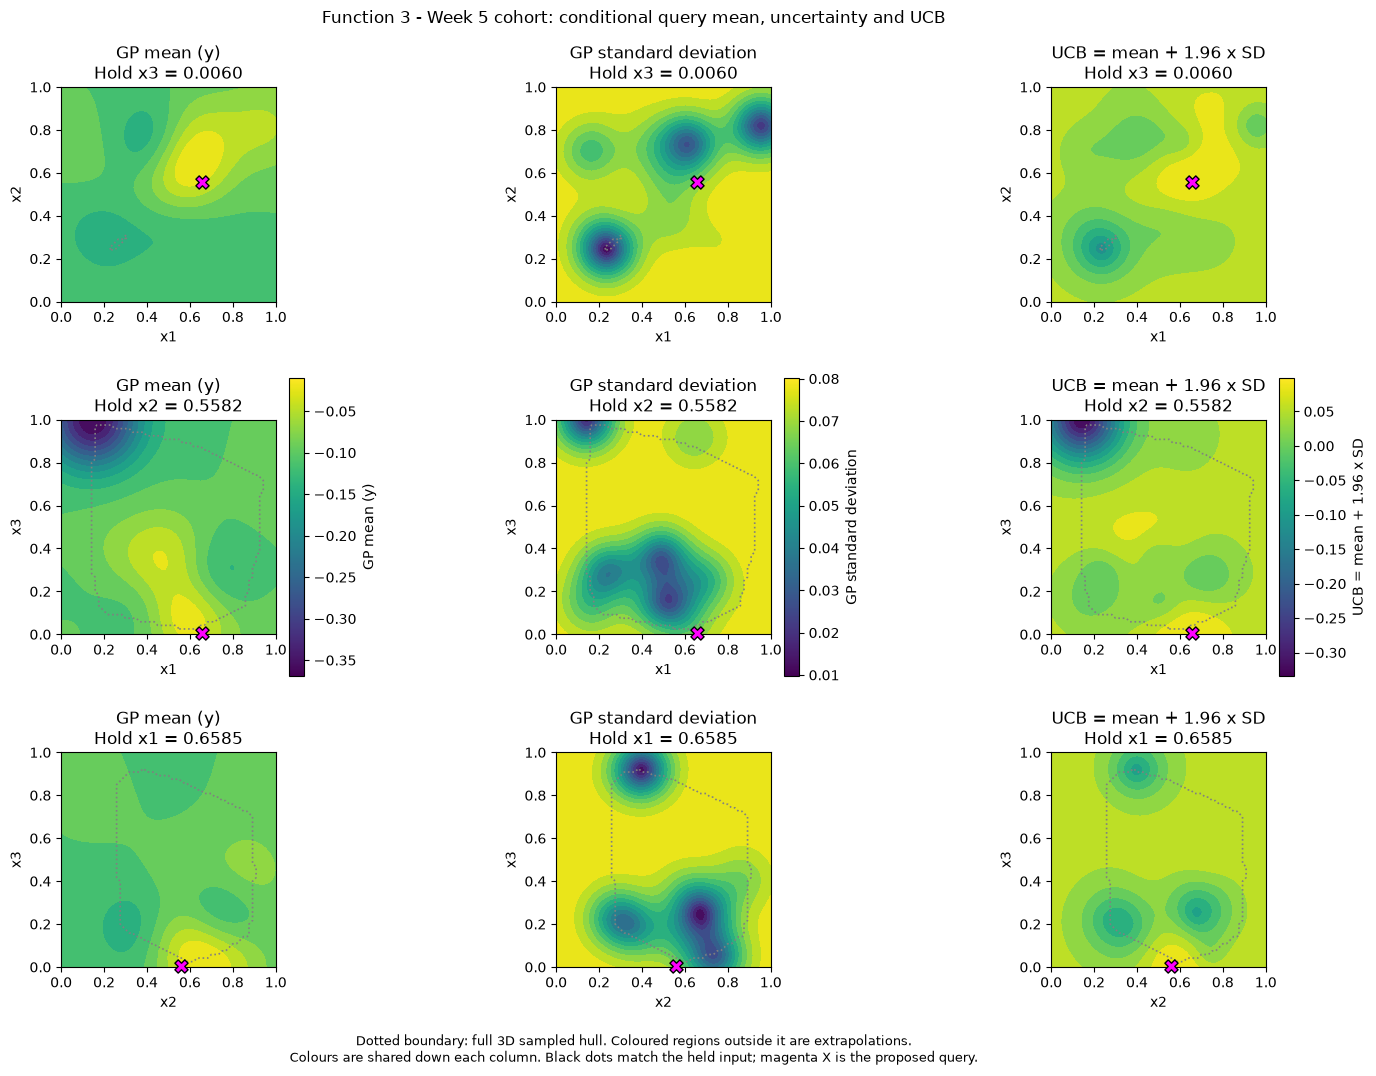

In [14]:
proposal_cloud = input_cloud(inputs, raw_y, anchor=anchor, suggestion=next_query,
    title='Function 3 - Week 5 cohort: observed inputs and proposed GP-UCB query')
for trace in proposal_cloud.data:
    if trace.name and 'Hypothetical' in trace.name:
        trace.name = trace.name.replace('Hypothetical', 'Proposed')
proposal_cloud.write_html(figures/'model-query-input-cloud.html', include_plotlyjs=True, config=PLOT_CONFIG)
proposal_cloud.show(config=PLOT_CONFIG)
query_planes = [plane_grid(selected_model, inputs, (a,b), next_query[c], uncertainty=True)
                for a,b,c in PLANE_AXES]
score_figure = plot_gp_score_sections(query_planes, inputs, weight=exploration_weight,
    suggestion=next_query, title='Function 3 - Week 5 cohort: conditional query mean, uncertainty and UCB')
score_figure.supxlabel(
    'Dotted boundary: full 3D sampled hull. Coloured regions outside it are extrapolations.\n'
    'Colours are shared down each column. Black dots match the held input; magenta X is the proposed query.',
    fontsize=9, y=0.02)
score_figure.savefig(figures/'model-query-proposal-sections.png', dpi=160, bbox_inches='tight')
display(score_figure)


## 10. Deploy and iterate

Deployment is not applicable. This comparison does not submit a query or replace the official
proposal. Keep the pinned peer snapshot distinct from future confirmed returns; peer data
add observations, not query opportunities. Revisit the assumptions when later evidence arrives.


In [15]:
analysis_summary = {
    'function': 3, 'week': 5, 'observations': len(data),
    'query_model': best_gp_name,
    'analysis_scope': 'cohort_snapshot_comparison',
    'proposal_status': 'exploratory_not_submitted', 'portal_input': portal_input,
    'point': next_query.tolist(), 'predicted_output': float(next_mean[0]),
    'posterior_std': float(next_std[0]), 'ucb_weight': exploration_weight,
    'candidate_source': proposal_source, 'candidate_count': len(scored),
    'inside_sampled_hull': inside_hull, 'best_observed_output': float(raw_y.max()),
    'gp_rmse': gaussian_process_rmse, 'baseline_rmse': baseline_rmse,
    'gp_baseline_rmse_ratio': relative_gp_error,
    'lowest_rmse_model': model_comparison.iloc[0]['Model'],
    'distinct_weight_choices': distinct_choices,
    'remaining_queries': remaining_queries(week_dir),
    'own_observations': int(own_mask.sum()), 'peer_observations': int(peer_mask.sum()),
    'noise_sensitivity': noise_rows,
    'model_comparison': model_comparison.to_dict(orient='records'),
    'fitted_kernel': str(selected_model.kernel_),
    'length_scales': np.atleast_1d(selected_model.kernel_.k2.length_scale).tolist(),
    'weight_sensitivity': exploration_sensitivity.to_dict(orient='records'),
}
print(json.dumps(analysis_summary, indent=2))


{
  "function": 3,
  "week": 5,
  "observations": 24,
  "query_model": "Gaussian process",
  "analysis_scope": "cohort_snapshot_comparison",
  "proposal_status": "exploratory_not_submitted",
  "portal_input": "0.658460-0.558234-0.006012",
  "point": [
    0.65846,
    0.558234,
    0.006012
  ],
  "predicted_output": -0.0332840209778196,
  "posterior_std": 0.0658848518885604,
  "ucb_weight": 1.96,
  "candidate_source": "Full input space",
  "candidate_count": 20497,
  "inside_sampled_hull": false,
  "best_observed_output": -0.034835313350078584,
  "gp_rmse": 0.04943963410874057,
  "baseline_rmse": 0.09775608125978519,
  "gp_baseline_rmse_ratio": 0.5057448444292233,
  "lowest_rmse_model": "Gaussian process",
  "distinct_weight_choices": 3,
  "remaining_queries": 9,
  "own_observations": 19,
  "peer_observations": 5,
  "noise_sensitivity": [
    {
      "Assumed noise fraction": 0.03,
      "Predicted output": -0.0389048111207342,
      "Posterior SD": 0.07030185631087219
    },
    {
  

## Read the pooled and paired comparisons together

Full pooled LOO scores describe all 24 rows. The paired section below keeps the 19 official
target values fixed and compares both policies on the same candidate pool. These checks are
conditional on a small adaptive sample and self-reported peer data, not an independent future test.


## Compare on the same official held-out targets

For each original observation, compare a prediction trained on the other 18 official rows with
one trained on those same 18 plus all five peer rows. Use each unchanged declared model family.
The scored target values are identical in both columns; peer rows can enter training, but never
replace those targets. This separates the training-data change from a change in the scored sample.
There is still no independent test set, and close peer points can make these checks optimistic.


In [16]:
own_inputs = own_data[input_columns].to_numpy(dtype=float)
own_y = own_data.y.to_numpy(dtype=float)
own_comparison, own_held_out, own_fitted = compare_models(models, own_inputs, own_y)
paired_rows = []
for name in models:
    pooled_own_predictions = held_out_predictions[name][own_mask]
    pd.testing.assert_series_equal(data.loc[own_mask, 'observation_id'].reset_index(drop=True), own_data.observation_id, check_names=False)
    paired_rows.append({
        'Model': name,
        'Own-target RMSE: 18 training rows': root_mean_squared_error(own_y, own_held_out[name]),
        'Own-target RMSE: 18 own + 5 peer training rows': root_mean_squared_error(own_y, pooled_own_predictions),
        'Own-target MAE: own training': mean_absolute_error(own_y, own_held_out[name]),
        'Own-target MAE: pooled training': mean_absolute_error(own_y, pooled_own_predictions),
    })
paired_comparison = pd.DataFrame(paired_rows)
display(paired_comparison.round(6))
own_gp_name = own_comparison.loc[gp_names, 'LOO RMSE'].idxmin()
own_selected = own_fitted[own_gp_name]
own_next = None
original_nb = __import__('nbformat').read(week_dir / 'model_predictions.ipynb', as_version=4)
for cell in original_nb.cells:
    for output in cell.get('outputs', []):
        text = output.get('text', '')
        if text.lstrip().startswith('{'):
            own_summary = json.loads(text)
            own_next = np.asarray(own_summary['point'], dtype=float)
if own_next is None:
    raise ValueError('The official notebook needs its saved proposal summary for this comparison.')
assert own_summary['observations'] == len(own_data) and own_summary['query_model'] == own_gp_name
assert np.isclose(own_summary['gp_rmse'], own_comparison.loc[own_gp_name,'LOO RMSE'])


C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better v

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better v

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better v

,Model,Own-target RMSE: 18 training rows,Own-target RMSE: 18 own + 5 peer training rows,Own-target MAE: own training,Own-target MAE: pooled training
0,Mean baseline,0.082160,0.081956,0.048173,0.049422
1,Linear regression,0.095242,0.091035,0.065211,0.070279
2,Ridge,0.085620,0.081932,0.053200,0.059643
3,Kernel ridge,0.094543,0.075755,0.066567,0.059055
4,Quadratic ridge,0.110504,0.095548,0.079598,0.073764
5,Gaussian process,0.085635,0.047850,0.055242,0.038978
6,GP: separate length scales,0.075703,0.084687,0.037542,0.067819


## Compare both fits on a common candidate pool

Use the same frozen union of the current candidate pool, the official coverage alternative and
both provisional points, excluding every observed pooled input at portal precision. Score it
with the official-data GP and the pooled-data GP, using weight 1.96 for both. This comparison
controls the candidate set; neither policy receives an extra point solely because its own
search geometry changed. The Function 3 models retain all three coordinates; any weak coordinate dependence remains a fitted assumption.

Also predict at the **two actual proposals**, retaining all three coordinates, to expose
changes in mean and uncertainty. Predicted values are not returned evaluations.


,Fit,Model,x1,x2,x3,posterior_mean,posterior_sd,ucb,Candidates
0,Official 19-row fit,GP: separate length scales,0.019633,0.050082,0.647040,-0.086909,0.085961,0.081575,20498
1,Pooled 24-row fit,Gaussian process,0.658460,0.558234,0.006012,-0.033284,0.065885,0.095850,20498


,Point,Fit,x1,x2,x3,Mean,SD,UCB
0,Official provisional point,Official 19-row fit,0.019633,0.050082,0.647040,-0.086909,0.085961,0.081575
1,Official provisional point,Pooled 24-row fit,0.019633,0.050082,0.647040,-0.099720,0.073943,0.045208
2,Cohort exploratory point,Official 19-row fit,0.658460,0.558234,0.006012,-0.075118,0.044655,0.012405
3,Cohort exploratory point,Pooled 24-row fit,0.658460,0.558234,0.006012,-0.033284,0.065885,0.095850


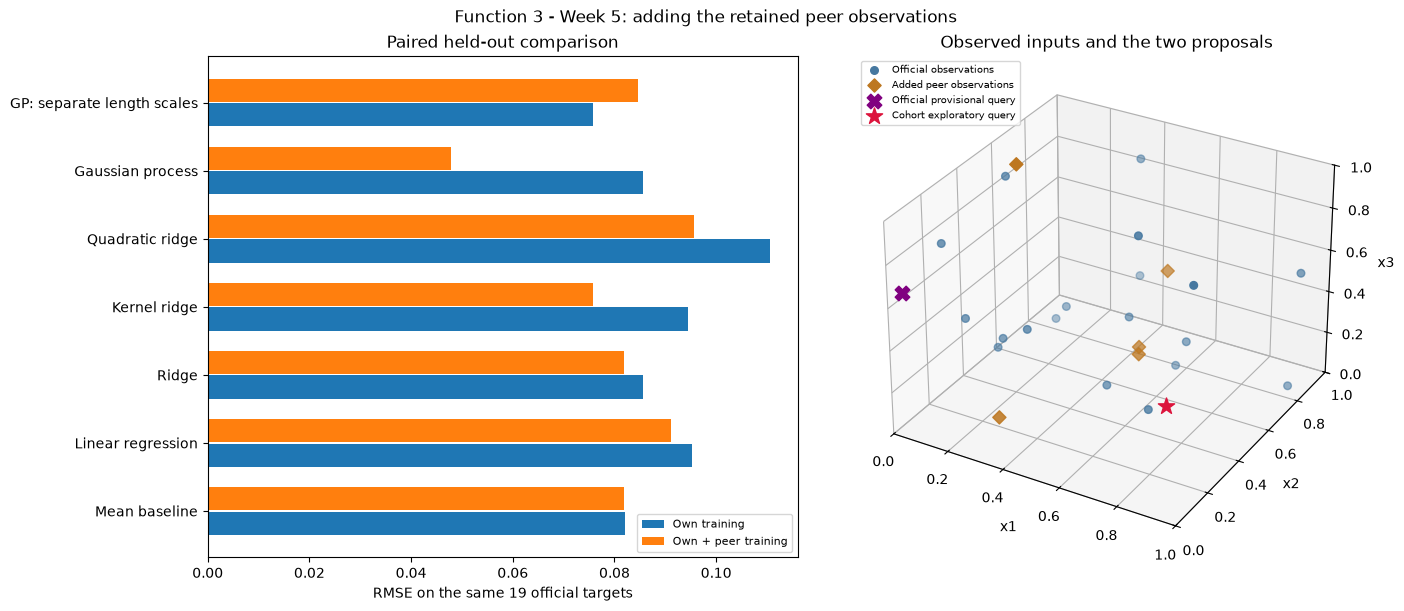

{
  "function": 3,
  "week": 5,
  "analysis": "official_vs_retained_cohort",
  "official": {
    "function": 3,
    "week": 5,
    "observations": 19,
    "query_model": "GP: separate length scales",
    "proposal_status": "proposed_not_submitted",
    "portal_input": "0.019633-0.050082-0.647040",
    "point": [
      0.019633,
      0.050082,
      0.64704
    ],
    "predicted_output": -0.08690945470370987,
    "posterior_std": 0.08596127663192338,
    "ucb_weight": 1.96,
    "candidate_source": "Full input space",
    "candidate_count": 20497,
    "inside_sampled_hull": false,
    "best_observed_output": -0.034835313350078584,
    "gp_rmse": 0.07570284931593903,
    "baseline_rmse": 0.08216049100123747,
    "gp_baseline_rmse_ratio": 0.9214021045078566,
    "lowest_rmse_model": "GP: separate length scales",
    "distinct_weight_choices": 3,
    "remaining_queries": 9,
    "model_comparison": [
      {
        "Model": "GP: separate length scales",
        "Training MAE": 0.0027002913

In [17]:
own_coverage = compare_coverage_batches(existing=own_inputs,
    cache_dir=week_dir/'.coverage-cache', max_queries=1, verbose=False)
own_coverage_point = own_coverage['proposed_batches'][1]
common_points = np.vstack([candidates[input_columns].to_numpy(), own_coverage_point, own_next, next_query]).round(6)
common_points = np.unique(np.clip(common_points,0,0.999999),axis=0)
common_points = common_points[[tuple(p) not in observed_coordinates for p in common_points]]
common_rows = []
for label, gp in [('Official 19-row fit', own_selected), ('Pooled 24-row fit', selected_model)]:
    common_scores = score_query_candidates(gp, common_points, weight=exploration_weight)
    top = common_scores.iloc[0]
    common_rows.append({'Fit':label, 'Model':own_gp_name if label.startswith('Official') else best_gp_name,
                        **top.to_dict(), 'Candidates':len(common_points)})
common_comparison = pd.DataFrame(common_rows)
display(common_comparison.round(6))
proposal_rows = []
for point_label, point in [('Official provisional point',own_next),('Cohort exploratory point',next_query)]:
    for fit_label, gp in [('Official 19-row fit',own_selected),('Pooled 24-row fit',selected_model)]:
        mean,std = gp.predict(point[None,:], return_std=True)
        proposal_rows.append({'Point':point_label,'Fit':fit_label,'x1':point[0],'x2':point[1],'x3':point[2],
                              'Mean':mean[0],'SD':std[0],'UCB':mean[0]+exploration_weight*std[0]})
proposal_comparison = pd.DataFrame(proposal_rows)
display(proposal_comparison.round(6))
fig=plt.figure(figsize=(14,6),layout='constrained')
axes=[fig.add_subplot(1,2,1),fig.add_subplot(1,2,2,projection='3d')]
positions=np.arange(len(paired_comparison))
axes[0].barh(positions-0.18,paired_comparison.iloc[:,1],height=0.34,label='Own training')
axes[0].barh(positions+0.18,paired_comparison.iloc[:,2],height=0.34,label='Own + peer training')
axes[0].set(yticks=positions,yticklabels=paired_comparison.Model,xlabel='RMSE on the same 19 official targets',title='Paired held-out comparison')
axes[0].legend(fontsize=8)
axes[1].scatter(*own_inputs.T,color='#4678a0',label='Official observations',s=30)
axes[1].scatter(*inputs[peer_mask].T,color='#bd7720',marker='D',label='Added peer observations',s=45)
axes[1].scatter(*own_next,color='purple',marker='X',s=110,label='Official provisional query')
axes[1].scatter(*next_query,color='crimson',marker='*',s=150,label='Cohort exploratory query')
axes[1].set(xlim=(0,1),ylim=(0,1),zlim=(0,1),xlabel='x1',ylabel='x2',zlabel='x3',title='Observed inputs and the two proposals')
axes[1].legend(fontsize=7,loc='upper left')
fig.suptitle('Function 3 - Week 5: adding the retained peer observations')
fig.savefig(figures/'official-versus-cohort.png',dpi=160,bbox_inches='tight')
plt.show()
comparison_summary = {'function':3,'week':5,'analysis':'official_vs_retained_cohort',
    'official':own_summary,'cohort':analysis_summary,
    'paired_targets':paired_comparison.to_dict(orient='records'),
    'common_candidates':common_comparison.to_dict(orient='records'),
    'proposal_predictions':proposal_comparison.to_dict(orient='records')}
print(json.dumps(comparison_summary,indent=2))


## Discussion: the peer data change which GP is preferred

The pooled incumbent remains **-0.034835313350078584**; none of the five retained peer returns
beats it. The important change is the fitted explanation. The official 19-row study favours
**separate length scales**, whereas the pooled 24-row study favours the **shared-length-scale GP**.

On the **same 19 official held-out targets**, the shared-length-scale GP's RMSE falls from
**0.085635** to **0.047850** (**44.1% lower**) after peer rows enter training.
The separate-length-scale GP instead worsens from **0.075703** to **0.084687**. More data have
not improved every explanation. The pooled winner's full 24-target RMSE is **0.049440**, against
its own mean baseline of **0.097756**; those full-dataset metrics score different rows from
the official 19-row study and are not a direct paired improvement measure.

The official proposal stays **`0.019633-0.050082-0.647040`**. The cohort policy proposes
**`0.658460-0.558234-0.006012`**, moving toward low x3 with x1 and x2 around 0.6. Its predicted
mean is **-0.033284**, only **0.001551** above the incumbent, while the latent-function SD is
**0.065885**. The UCB score at weight 1.96 is **0.095850**. Uncertainty is much larger than the
small predicted mean gain, so this remains an exploratory suggestion. Both actual proposals
lie outside the pooled sampled 3D hull; the conditional views label their extrapolation.

The same two policies choose these respective points on the **same 20,498 candidate locations**.
The change is therefore not solely an artefact of separately generated candidate pools. At the
original proposal, the pooled GP predicts mean **-0.099720**, SD **0.073943**, and UCB **0.045208**,
so it places substantially less acquisition value there than at the low-x3 alternative.

All four tested exploration weights favour the broad low-x3 region, with three distinct
locations; weights 1.96 and 3.0 agree on the displayed proposal. Noise sensitivity remains
material: at the same proposed point, changing the assumed noise fraction from 0.03 to 0.30
moves its mean from about **-0.038905** to **-0.076600**. The selected pooled kernel has a fitted
shared length scale of about **0.151**, unlike the official separate-scale fit's two upper-bound
length scales. This comparison does not prove any coordinate is irrelevant or establish the
true function, optimum, or noise level.

These five peer rows are frozen public self-reports from 20 October, not a refreshed cohort
return or an independent test set. Model selection reuses the same small adaptive sample.
The pooled result motivates reviewing the low-x3 region, while **the official notebooks,
CSV and provisional proposal remain unchanged and no portal submission is performed**.
